Early Classifier Validation
===========================

This notebook contains some early experiments validating the baseline classifier approach. None of these plots ended up in the paper. This work was the basis for the final classifier testing in another notebook.

In [1]:
import numpy as np
import math
import json
import itertools
import statistics
from pathlib import Path
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
meas = {}
for f in Path('../data').glob('*.json'):
    d = json.loads(f.read_bytes())
    d['adc1'] = np.array(d['adc1'])
    d['adc2'] = np.array(d['adc2'])
    d['var1'] = np.array(d['var1'])
    d['var2'] = np.array(d['var2'])
    meas[d['meta']] = d

for n in sorted(meas):
    print(n)

74lvc_mesh_new_p0.3mm
74lvc_mesh_new_p0.4mm
74lvc_mesh_new_p0.6mm
74lvc_mesh_new_p1.0mm
74lvc_mesh_p0.3mm
74lvc_mesh_p0.3mm_flip
74lvc_mesh_p0.3mm_term
74lvc_mesh_p0.4mm
74lvc_mesh_p0.6mm
74lvc_mesh_p1.0mm
74lvc_new2_mesh_p0.3mm
74lvc_new2_mesh_p0.4mm
74lvc_new2_mesh_p0.6mm
74lvc_new2_mesh_p1.0mm
74lvc_new2_open
74lvc_new2_risetime
74lvc_new_mesh_p0.3mm
74lvc_new_mesh_p0.3mm_flip
74lvc_new_mesh_p0.3mm_term
74lvc_new_open
74lvc_open
long_sample_a_bwd
long_sample_a_bwd_term
long_sample_a_bwd_term_short
long_sample_a_fwd
long_sample_a_fwd_term
long_sample_a_fwd_term_short
long_sample_a_mod_flip
long_sample_a_mod_flip_term
long_sample_a_mod_flip_term_short
long_sample_a_mod_fwd
long_sample_a_mod_fwd_term
long_sample_a_mod_fwd_term_short
long_sample_b_bwd
long_sample_b_bwd_term
long_sample_b_fwd
long_sample_b_fwd_term
long_sample_b_fwd_term_short
long_sample_b_post_2mod_1
long_sample_b_post_2mod_10
long_sample_b_post_2mod_2
long_sample_b_post_2mod_3
long_sample_b_post_2mod_4
long_sample_b_p

Baseline threshold set at 0.846000
Within class: 0.999±0.000683 max: 1
Cross class: 0.693±0.0692 max: 0.764
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.013368210079


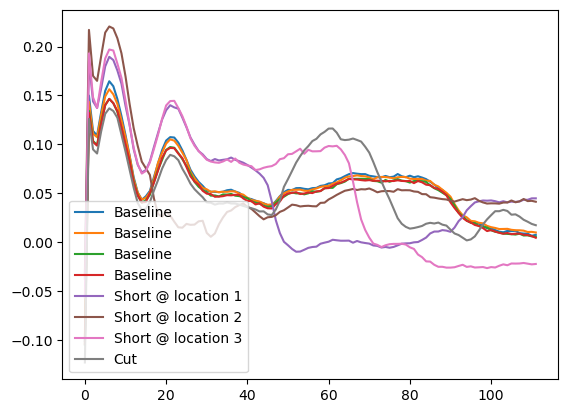

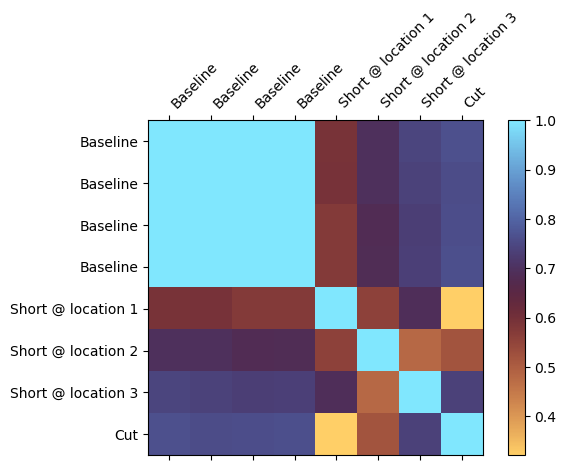

In [124]:
roi = 530, 650
curves = { 'run3_pi3hdx_manip_baseline1': ('Baseline', 'black', '-'),
            'run3_pi3hdx_manip_baseline2': ('Baseline', 'black', '-'),
            'run3_pi3hdx_manip_baseline3': ('Baseline', 'black', '-'),
            'run3_pi3hdx_manip_baseline4': ('Baseline', 'black', '-'),
            'run3_pi3hdx_manip_short1':    ('Short @ location 1', 'red', '-'),
            'run3_pi3hdx_manip_short2':    ('Short @ location 2', 'red', '--'),
            'run3_pi3hdx_manip_short3':    ('Short @ location 3', 'red', '-.'),
            'run3_pi3hdx_manip_cut':       ('Cut', 'blue', '-'),
        }

#for name, (label, _color, _linestyle) in curves.items():
#    d = meas[name]['adc1'][roi[0]:roi[1]]
#    plt.plot(d, label=label)
#plt.legend()

n = roi[1]-roi[0]
d = np.zeros((len(curves), n))
for i, name in enumerate(curves):
    d[i] = meas[name]['adc1'][roi[0]:roi[1]]

labels = [label for label, _color, _linestyle in curves.values()]

# Normalize each curve such that its mean is at 0 and its min is at -1
deltas = d[:,1:]
deltas -= np.repeat(deltas.mean(axis=1)[:,np.newaxis], n-1, axis=1)
deltas /= -np.repeat(deltas.min(axis=1)[:,np.newaxis], n-1, axis=1)

# Align all curves such that the trace starts where the trace crosses 0.5
roi_refined = round(np.mean(n - 1 - np.argmax(deltas[:,::-1] < -0.5, axis=1))), n
deltas = deltas[:,roi_refined[0]:roi_refined[1]]

#corr = np.zeros((len(deltas), len(deltas)))
#for i, j in itertools.product(range(len(deltas)), range(len(deltas))):
#    corr[i, j] = np.correlate(deltas[i], deltas[j])[0] / np.sqrt(np.correlate(deltas[i], deltas[i])[0] * np.correlate(deltas[j], deltas[j])[0])

corr = np.corrcoef(deltas)

fig, ax = plt.subplots()
for x, lab in zip(deltas, labels):
    ax.plot(x, label=lab)
ax.legend()

within_class = corr[:4, :4][np.triu_indices(4)]
cross_class = corr[4:, :4].flatten()

cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
print(f'Baseline threshold set at {threshold:.6f}')

for name, data in [('Within', within_class), ('Cross', cross_class)]:
    print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} max: {np.max(data):.3g}')
print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')

#corr -= np.min(corr)
#corr /= np.max(corr)

#for i in range(len(corr[0])):
#    corr[i, i] = math.nan

fig, ax = plt.subplots()
cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
fig.colorbar(cax)
ax.set_xticks(list(range(len(labels))))
ax.set_xticklabels(labels, rotation=45, ha='left')
ax.set_yticks(list(range(len(labels))))
ax.set_yticklabels(labels)
fig.tight_layout()
fig.savefig('../../paper/manip_pearson_corr.pdf')
None

Baseline threshold set at 0.996519
Within class: 0.999±0.00123
Cross class: 0.994±0.00104
Baseline false negative probability: 0.036804692576
Baseline false positive probability: 0.017889448821


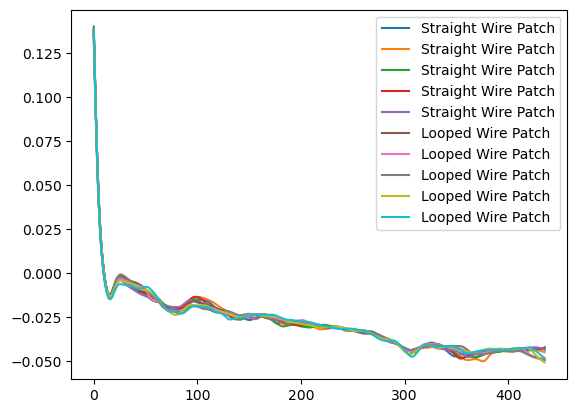

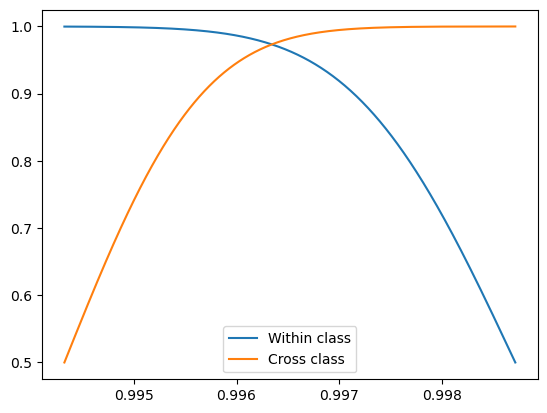

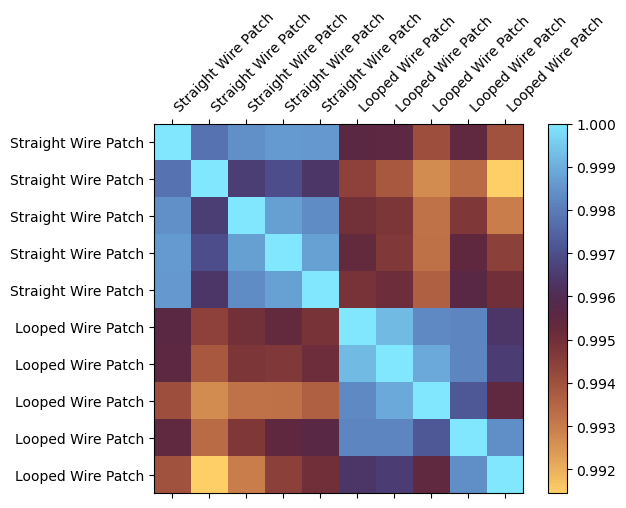

In [121]:
roi = 200, 650
curves = {
            'long_sample_b_post_demod_1': ('Straight Wire Patch', 'black', '-', 1),
            'long_sample_b_post_demod_2': ('Straight Wire Patch', 'black', '-', 1),
            'long_sample_b_post_demod_4': ('Straight Wire Patch', 'black', '-', 1),
            'long_sample_b_post_demod_6': ('Straight Wire Patch', 'black', '-', 1),
            'long_sample_b_post_demod_8': ('Straight Wire Patch', 'black', '-', 1),
            'long_sample_b_post_2modb_1': ('Looped Wire Patch', 'red', '-', 1),
            'long_sample_b_post_2modb_2': ('Looped Wire Patch', 'red', '-', 1),
            'long_sample_b_post_2modb_4': ('Looped Wire Patch', 'red', '-', 1),
            'long_sample_b_post_2modb_6': ('Looped Wire Patch', 'red', '-', 1),
            'long_sample_b_post_2modb_8': ('Looped Wire Patch', 'red', '-', 1),}


#fig, ax = plt.subplots()
#for name, (label, _color, _linestyle, _foo) in curves.items():
#    d = meas[name]['adc2'][roi[0]:roi[1]]
#    ax.plot(d, label=label)
#ax.legend()

n = roi[1]-roi[0]
d = np.zeros((len(curves), n))
for i, name in enumerate(curves):
    d[i] = meas[name]['adc2'][roi[0]:roi[1]]

labels = [label for label, _color, _linestyle, _foo in curves.values()]

# Normalize each curve such that its mean is at 0 and its min is at -1
deltas = d[:,1:]
deltas -= np.repeat(deltas.mean(axis=1)[:,np.newaxis], n-1, axis=1)
deltas /= np.repeat(deltas.max(axis=1)[:,np.newaxis], n-1, axis=1)

# Align all curves such that the trace starts where the trace crosses 0.5
roi_refined = round(np.mean(n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), n
n = roi_refined[1] - roi_refined[0]
deltas = deltas[:,roi_refined[0]:roi_refined[1]]

for i in range(len(deltas)):
    t = list(range(n-1))
    spl = interpolate.make_smoothing_spline(t, deltas[i], lam=100)
    deltas[i] = spl(t)

fig, ax = plt.subplots()
for x, lab in zip(deltas, labels):
    ax.plot(x, label=lab)
ax.legend()

#corr = np.zeros((len(deltas), len(deltas)))
#for i, j in itertools.product(range(len(deltas)), range(len(deltas))):
#    corr[i, j] = np.correlate(deltas[i], deltas[j])[0] / np.sqrt(np.correlate(deltas[i], deltas[i])[0] * np.correlate(deltas[j], deltas[j])[0])

corr = np.corrcoef(deltas)

within_class = corr[:5, :5][np.triu_indices(4)]
cross_class = corr[5:, :5].flatten()

cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
print(f'Baseline threshold set at {threshold:.6f}')

for name, data in [('Within', within_class), ('Cross', cross_class)]:
    print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g}')
print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')

xs = np.linspace(np.mean(within_class), np.mean(cross_class), 1000)
ys_w = [1 - cdf(x, np.mean(within_class), np.std(within_class)) for x in xs]
ys_c = [cdf(x, np.mean(cross_class), np.std(cross_class)) for x in xs]
fig, ax = plt.subplots()
ax.plot(xs, ys_w, label='Within class')
ax.plot(xs, ys_c, label='Cross class')
ax.legend()
fig.savefig('../paper/patch_cdf.pdf')

#for i in range(len(corr[0])):
#    corr[i, i] = math.nan
#corr -= np.min(corr)
#corr /= np.max(corr)
fig, ax = plt.subplots()
cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
fig.colorbar(cax)
ax.set_xticks(list(range(len(labels))))
ax.set_xticklabels(labels, rotation=45, ha='left')
ax.set_yticks(list(range(len(labels))))
ax.set_yticklabels(labels)
fig.savefig('../../paper/patch_pearson_corr.pdf')
None
